# Unit 8 — Membangun Skenario Model
**Kode unit:** J.62DMI00.012.1 · **Acuan:** SKKNI No. 299 Tahun 2020 (Ilmuwan Data) · **Proyek:** Prediksi Arah Harian IHSG

> Notebook ini merancang **skenario pengujian**: desain validasi silang deret waktu, tiga baseline, lima skenario algoritma beserta hiperparameter awal dan ruang *tuning*, metrik, serta aturan pemilihan model. Desain disimpan sebagai konfigurasi `reports/model_scenarios.json` yang dieksekusi apa adanya di Unit 9.

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

warnings.filterwarnings('ignore')
pd.set_option('display.width', 140)
pd.set_option('display.max_columns', 40)
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')

RAW = Path('../data/raw/market_data.csv')
PROC = Path('../data/processed')
FIG = Path('../figures')
REP = Path('../reports')
MOD = Path('../models')
for p in (PROC, FIG, REP, MOD):
    p.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
EDA_END = '2022-12-31'
C_UP, C_DOWN, C_NAVY, C_ACCENT, C_GREY = '#1a9850', '#d73027', '#1f3a5f', '#e08214', '#8c8c8c'
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'font.size': 10, 'axes.titleweight': 'bold',
})

In [2]:
from sklearn.model_selection import TimeSeriesSplit

train = pd.read_csv(PROC / 'train.csv', parse_dates=['Date'])
FEATURES = [c for c in train.columns if c not in ('Date', 'ret_next', 'y')]
print(f'Data latih: {len(train):,} hari, {len(FEATURES)} fitur, proporsi naik {train.y.mean():.1%}')

Data latih: 3,148 hari, 16 fitur, proporsi naik 54.6%


## 1. Desain validasi: `TimeSeriesSplit` (5 lipatan, *gap* 1 hari)

Validasi silang biasa (*K-Fold* acak) akan melatih model dengan data **sesudah** periode validasi — tidak mungkin
terjadi di dunia nyata. `TimeSeriesSplit` selalu melatih dengan masa lalu dan menguji pada periode sesudahnya
(*expanding window*). *Gap* 1 hari membuang baris yang labelnya tumpang tindih dengan periode validasi.

,Lipatan,Periode latih,n latih,Periode validasi,n validasi,Proporsi naik (validasi)
0,1,Mar 2010 – Apr 2012,527,Apr 2012 – Jun 2014,524,0.5668
1,2,Mar 2010 – Jun 2014,1051,Jun 2014 – Aug 2016,524,0.5611
2,3,Mar 2010 – Aug 2016,1575,Aug 2016 – Oct 2018,524,0.5248
3,4,Mar 2010 – Oct 2018,2099,Oct 2018 – Dec 2020,524,0.5324
4,5,Mar 2010 – Dec 2020,2623,Dec 2020 – Jan 2023,524,0.5267


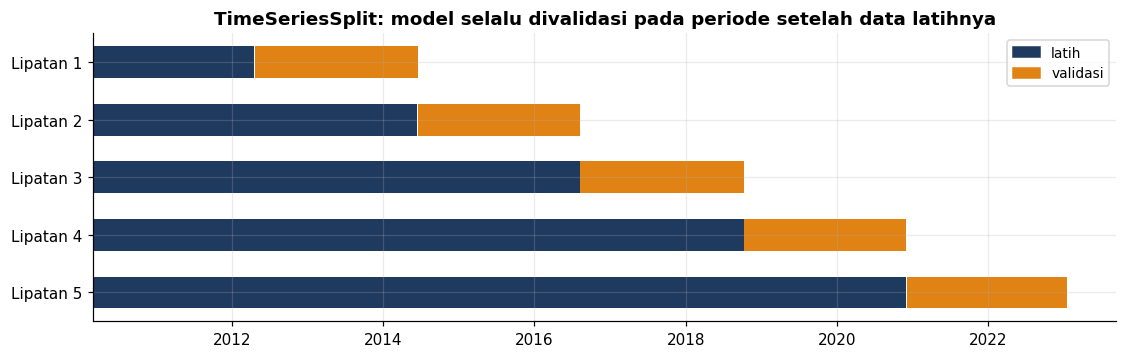

In [3]:
CV = {'method': 'TimeSeriesSplit', 'n_splits': 5, 'gap': 1}
tscv = TimeSeriesSplit(n_splits=CV['n_splits'], gap=CV['gap'])
folds = []
for k, (tr, va) in enumerate(tscv.split(train), 1):
    folds.append({'Lipatan': k,
                  'Periode latih': f'{train.Date.iloc[tr[0]]:%b %Y} – {train.Date.iloc[tr[-1]]:%b %Y}', 'n latih': len(tr),
                  'Periode validasi': f'{train.Date.iloc[va[0]]:%b %Y} – {train.Date.iloc[va[-1]]:%b %Y}', 'n validasi': len(va),
                  'Proporsi naik (validasi)': train.y.iloc[va].mean(),
                  '_tr': (train.Date.iloc[tr[0]], train.Date.iloc[tr[-1]]), '_va': (train.Date.iloc[va[0]], train.Date.iloc[va[-1]])})
fold_df = pd.DataFrame(folds)
display(fold_df.drop(columns=['_tr', '_va']))

fig, ax = plt.subplots(figsize=(12, 3.4))
for _, f in fold_df.iterrows():
    k = f['Lipatan']
    ax.barh(k, (f['_tr'][1] - f['_tr'][0]).days, left=f['_tr'][0], color=C_NAVY, height=0.55)
    ax.barh(k, (f['_va'][1] - f['_va'][0]).days, left=f['_va'][0], color=C_ACCENT, height=0.55)
ax.set_yticks(fold_df['Lipatan']); ax.set_yticklabels([f'Lipatan {k}' for k in fold_df['Lipatan']])
ax.invert_yaxis()
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=C_NAVY, label='latih'), Patch(color=C_ACCENT, label='validasi')], loc='upper right', fontsize=9)
ax.set_title('TimeSeriesSplit: model selalu divalidasi pada periode setelah data latihnya')
plt.savefig(FIG / '08_timeseries_cv.png')
plt.show()

## 2. Metrik evaluasi

| Metrik | Rumus / makna | Peran |
|---|---|---|
| F1-macro | rata-rata F1 kelas Naik dan Turun | **Metrik utama pemilihan model** (adil untuk kedua kelas) |
| ROC-AUC | peluang skor hari naik > skor hari turun | Metrik kedua (kualitas peringkat probabilitas) |
| Accuracy | proporsi prediksi benar | Mudah dipahami pemangku kepentingan |
| Precision/Recall macro | ketepatan dan kelengkapan per kelas | Diagnosis bias ke satu kelas |

## 3. Baseline dan skenario model

Baseline wajib dikalahkan agar model dianggap bernilai tambah. **B3** adalah baseline domain yang kuat: aturan
sederhana "IHSG besok searah dengan S&P 500 semalam" — model ML harus menunjukkan apakah ia memberi nilai lebih dari
aturan sesederhana ini.

In [4]:
scenarios = {
    'cv': CV,
    'primary_metric': 'f1_macro',
    'secondary_metric': 'roc_auc',
    'features': FEATURES,
    'baselines': [
        {'id': 'B1', 'nama': 'Mayoritas', 'estimator': 'DummyClassifier', 'params': {'strategy': 'most_frequent'},
         'alasan': 'Selalu menebak kelas terbanyak di data latih'},
        {'id': 'B2', 'nama': 'Acak berstrata', 'estimator': 'DummyClassifier',
         'params': {'strategy': 'stratified', 'random_state': RANDOM_STATE}, 'alasan': 'Tebakan acak sesuai proporsi kelas'},
        {'id': 'B3', 'nama': 'Ikuti arah S&P 500', 'estimator': 'rule:sp500_ret', 'params': {},
         'alasan': 'Heuristik domain: Naik jika S&P 500 naik semalam'},
    ],
    'models': [
        {'id': 'S1', 'nama': 'Logistic Regression', 'estimator': 'LogisticRegression', 'scaling': True,
         'params': {'C': 1.0, 'class_weight': 'balanced', 'max_iter': 2000},
         'grid': {'C': [0.01, 0.1, 1.0, 10.0]}, 'alasan': 'Model linear, koefisien dapat diinterpretasi'},
        {'id': 'S2', 'nama': 'Decision Tree', 'estimator': 'DecisionTreeClassifier', 'scaling': False,
         'params': {'max_depth': 4, 'min_samples_leaf': 50, 'class_weight': 'balanced', 'random_state': RANDOM_STATE},
         'grid': {'max_depth': [3, 4, 6], 'min_samples_leaf': [20, 50, 100]}, 'alasan': 'Aturan keputusan eksplisit'},
        {'id': 'S3', 'nama': 'Random Forest', 'estimator': 'RandomForestClassifier', 'scaling': False,
         'params': {'n_estimators': 300, 'max_depth': 5, 'min_samples_leaf': 20, 'class_weight': 'balanced',
                    'random_state': RANDOM_STATE, 'n_jobs': -1},
         'grid': {'max_depth': [3, 5, 8], 'min_samples_leaf': [10, 20, 50]}, 'alasan': 'Ensemble robust, menangkap interaksi'},
        {'id': 'S4', 'nama': 'Gradient Boosting', 'estimator': 'GradientBoostingClassifier', 'scaling': False,
         'params': {'n_estimators': 150, 'max_depth': 2, 'learning_rate': 0.05, 'subsample': 0.8, 'random_state': RANDOM_STATE},
         'grid': {'n_estimators': [150, 300], 'max_depth': [2, 3], 'learning_rate': [0.05, 0.1]},
         'alasan': 'Boosting kuat untuk data tabular'},
        {'id': 'S5', 'nama': 'SVM (RBF)', 'estimator': 'SVC', 'scaling': True,
         'params': {'C': 1.0, 'gamma': 'scale', 'class_weight': 'balanced', 'probability': True, 'random_state': RANDOM_STATE},
         'grid': {'C': [0.3, 1.0, 3.0], 'gamma': ['scale', 0.01]}, 'alasan': 'Batas keputusan non-linear'},
    ],
    'selection_rule': ('Pilih skenario S1–S5 dengan F1-macro rata-rata CV tertinggi (seri → ROC-AUC lebih tinggi). '
                       'Lakukan grid search pada skenario terpilih dengan CV yang sama; grid selalu memuat parameter awal. '
                       'Model final dilatih ulang pada seluruh data latih.'),
}
with open(REP / 'model_scenarios.json', 'w', encoding='utf-8') as f:
    json.dump(scenarios, f, ensure_ascii=False, indent=2)

table = pd.DataFrame([{'ID': s['id'], 'Skenario': s['nama'], 'Standardisasi': 'Ya' if s.get('scaling') else 'Tidak',
                       'Parameter awal': ', '.join(f'{k}={v}' for k, v in s['params'].items() if k not in ('random_state', 'n_jobs', 'max_iter')),
                       'Ruang tuning': ' × '.join(f'{k}{v}' for k, v in s.get('grid', {}).items()) or '-',
                       'Alasan': s['alasan']} for s in scenarios['baselines'] + scenarios['models']])
display(table)
n_fits = sum(int(np.prod([len(v) for v in s['grid'].values()])) for s in scenarios['models'])
print(f'Tersimpan -> {REP / "model_scenarios.json"} | kombinasi tuning (jika semua dituning): {n_fits}')

,ID,Skenario,Standardisasi,Parameter awal,Ruang tuning,Alasan
0,B1,Mayoritas,Tidak,strategy=most_frequent,-,Selalu menebak kelas terbanyak di data latih
1,B2,Acak berstrata,Tidak,strategy=stratified,-,Tebakan acak sesuai proporsi kelas
2,B3,Ikuti arah S&P 500,Tidak,,-,Heuristik domain: Naik jika S&P 500 naik semalam
3,S1,Logistic Regression,Ya,"C=1.0, class_weight=balanced","C[0.01, 0.1, 1.0, 10.0]","Model linear, koefisien dapat diinterpretasi"
4,S2,Decision Tree,Tidak,"max_depth=4, min_samples_leaf=50, class_weight...","max_depth[3, 4, 6] × min_samples_leaf[20, 50, ...",Aturan keputusan eksplisit
5,S3,Random Forest,Tidak,"n_estimators=300, max_depth=5, min_samples_lea...","max_depth[3, 5, 8] × min_samples_leaf[10, 20, 50]","Ensemble robust, menangkap interaksi"
6,S4,Gradient Boosting,Tidak,"n_estimators=150, max_depth=2, learning_rate=0...","n_estimators[150, 300] × max_depth[2, 3] × lea...",Boosting kuat untuk data tabular
7,S5,SVM (RBF),Ya,"C=1.0, gamma=scale, class_weight=balanced, pro...","C[0.3, 1.0, 3.0] × gamma['scale', 0.01]",Batas keputusan non-linear


Tersimpan -> ../reports/model_scenarios.json | kombinasi tuning (jika semua dituning): 36


## 4. Penanganan isu khusus

| Isu | Penanganan dalam skenario |
|---|---|
| Ketidakseimbangan kelas ringan (±54% naik) | `class_weight='balanced'` pada model yang mendukung; F1-macro sebagai metrik utama |
| Skala fitur berbeda (VIX ≈ 10–80, return ≈ ±3) | `StandardScaler` di dalam *pipeline* untuk Logistic Regression dan SVM |
| Kebocoran antarlipatan | Standardisasi di-*fit* ulang pada setiap lipatan latih (otomatis oleh `Pipeline`) |
| *Overfitting* pada sinyal lemah | Model pohon dibatasi (`max_depth`, `min_samples_leaf`), *learning rate* kecil |
| Keterulangan | `random_state = 42` pada semua komponen acak |

## Ringkasan Unit 8
Skenario pengujian terdiri atas **3 baseline + 5 algoritma**, divalidasi dengan `TimeSeriesSplit` 5 lipatan
(*gap* 1). Pemilihan berdasarkan **F1-macro**, dengan aturan tertulis sebelum eksperimen dijalankan.